In [1]:
from examples.mueller_brown_driver import MuellerBrownRunner
from qcelemental.models.v2 import Molecule

import psi4.driver.constants as const
import matplotlib.pyplot as plt
import numpy as np
import math

In [2]:
def get_evf_step(g, h):

    evals, evecs = np.linalg.eigh(h)

    lammda = (evals[0] + 2 * evals[1]) / 4.0

    F = np.matmul(evecs.T, g)

    xi = F / (lammda - evals)

    return np.matmul(evecs, xi)

In [3]:
def ring_polymer_gradient(ring_polymer):
    positions = np.array([
        bead.geometry.flatten()
        for bead in ring_polymer
    ])

    gradients = np.array([
        runner.gradient(bead).flatten()
        for bead in ring_polymer
    ])

    spring_grad = np.zeros_like(positions)

    spring_grad[0] = positions[0] - positions[1]
    spring_grad[-1] = positions[-1] - positions[-2]

    spring_grad[1:-1] = (
        2 * positions[1:-1]
        - positions[:-2]
        - positions[2:]
    )

    return (gradients + 10000 * spring_grad).flatten()

In [4]:
def ring_polymer_hessian(ring_polymer):
    n = len(ring_polymer)
    d = 3

    H = np.zeros((n * d, n * d))
    I = 10000 * np.eye(d)

    for i, bead in enumerate(ring_polymer):
        s = slice(i * d, (i + 1) * d)

        H[s, s] = runner.hessian(bead)

        if i > 0:
            H[s, s] += I

        if i < n - 1:
            H[s, s] += I

            t = slice((i + 1) * d, (i + 2) * d)

            H[s, t] = -I
            H[t, s] = -I

    return H

In [5]:
def get_ring_polymer_step(ring_polymer):
    return get_evf_step(ring_polymer_gradient(ring_polymer), ring_polymer_hessian(ring_polymer))

In [6]:
def show_ring_polymer_path(ring_polymer):
    geometries = np.array([bead.geometry[0] for bead in ring_polymer])

    x = np.linspace(-2, 2, 200)
    y = np.linspace(-1, 3, 200)
    X, Y = np.meshgrid(x, y)

    Z = np.vectorize(runner.en)(X, Y, 0)

    Zlog = np.log(Z + 180)

    vmin = 3.0
    vmax = 8.0

    t = np.linspace(0, 1, 50)
    levels = vmin + (8.0 - 3.0) * t**5

    plt.contourf(
        X, Y, Zlog,
        levels=levels,
        cmap='viridis',
        extend='max'
    )

    plt.scatter(
        geometries[:, 0],
        geometries[:, 1],
        color="black",
        s=1,
        zorder=5,
        label="Instanton Path"
    )

    plt.colorbar(label='log(Z - Zmin)')
    plt.show()

In [7]:
b2a = const.bohr2angstroms
x, y, z = -0.892, 0.564, 0

molstr = "O " + str(x*b2a) + " " + str(y*b2a) + " " + str(z*b2a)
runner = MuellerBrownRunner()

In [8]:
max_iterations = 500
mols = [Molecule.from_data(molstr)]
rms = []

for i in range(max_iterations):
    mol = mols[-1]

    g = runner.gradient(mol)
    h = runner.hessian(mol)

    step = get_evf_step(g,h)

    grad_rms = np.linalg.norm(g) / np.sqrt(g.size)
    rms.append(grad_rms)

    if grad_rms < 1e-6:
        break
    new_geometry = mol.geometry + step.reshape(mol.geometry.shape)

    mols.append(mol.model_copy(
        update={"geometry": new_geometry}
    ))

-0.892 0.564 0.0
-0.8137031839123272 0.6570310815730224 0.0
-0.8265052892397016 0.624668465806271 0.0
-0.8219762074725172 0.6247097575284847 0.0
-0.8220421298531198 0.6242918518436684 0.0
-0.821998860639533 0.6243178694347788 0.0
-0.8220021073512952 0.6243122933837224 0.0
-0.8220014995332674 0.6243128819258483 0.0
-0.8220015675472945 0.6243127931430024 0.0
-0.8220015576321201 0.6243128041558513 0.0


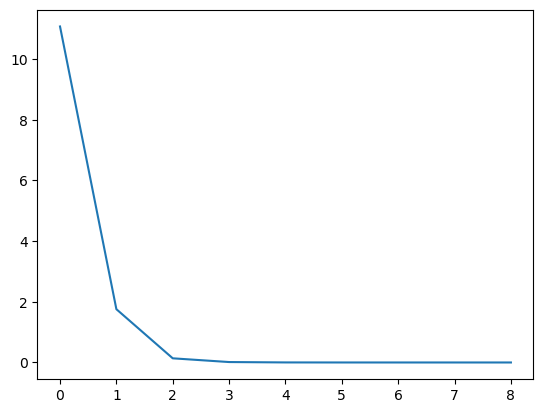

In [9]:
plt.plot(rms[1:])
plt.show()

In [16]:
mol = mols[-1]
ring_polymer = []
h = runner.hessian(mol)
evals, evecs = np.linalg.eigh(h)
qi = evecs[:,0]
n_beads = 16

for i in range(n_beads):
    pf = 0.2 * np.cos(np.pi*i/(n_beads-1))
    new_geometry = mol.geometry + pf * qi.reshape(mol.geometry.shape)
    ring_polymer.append(mol.model_copy(
        update={"geometry": new_geometry}
    ))

geometries = np.array([bead.geometry[0] for bead in ring_polymer])

In [17]:
max_iterations = 50
rps = [ring_polymer]
rms = []

for i in range(max_iterations):
    rp = rps[-1]

    g = ring_polymer_gradient(rp)
    h = ring_polymer_hessian(rp)

    step = get_evf_step(g,h)

    grad_rms = np.linalg.norm(g) / np.sqrt(g.size)
    rms.append(grad_rms)

    if grad_rms < 1e-6:
        break

    new_rp = []
    
    new_bead_geometries = step.reshape((-1, rp[0].symbols.size, 3))
    
    for i in range(len(rp)):
        s = slice(i * 3, (i + 1) * 3)
        new_geometry = rp[i].geometry + new_bead_geometries[i]
        new_rp.append(mol.model_copy(
            update={"geometry": new_geometry}
        ))

    rps.append(new_rp)

-0.9742808283148127 0.7539701360748263 0.0
-0.9709531608918895 0.7511368122899434 0.0
-0.961115593657422 0.7427606707804899 0.0
-0.9451980755054411 0.7292077891236154 0.0
-0.923896278359915 0.7110704932816668 0.0
-0.8981411929734664 0.6891414701153389 0.0
-0.8690584401640948 0.664379123164128 0.0
-0.837919075784101 0.6378656858127258 0.0
-0.8060840394801393 0.6107599224989768 0.0
-0.7749446751001454 0.5842464851475747 0.0
-0.7458619222907739 0.5594841381963639 0.0
-0.7201068369043254 0.5375551150300358 0.0
-0.6988050397587992 0.5194178191880873 0.0
-0.6828875216068182 0.5058649375312126 0.0
-0.6730499543723507 0.4974887960217592 0.0
-0.6697222869494276 0.49465547223687634 0.0
-0.9173158217558373 0.8890818608002121 -2.587326549025813e-16
-0.905999439609523 0.8719260078704321 -2.302045852607887e-16
-0.8827844888024693 0.838324058118336 -8.746107372282108e-17
-0.8468775612589572 0.7901396364758376 -1.372678405314167e-16
-0.7984202552250899 0.7312192098957007 -8.440332694086687e-18
-0.7396

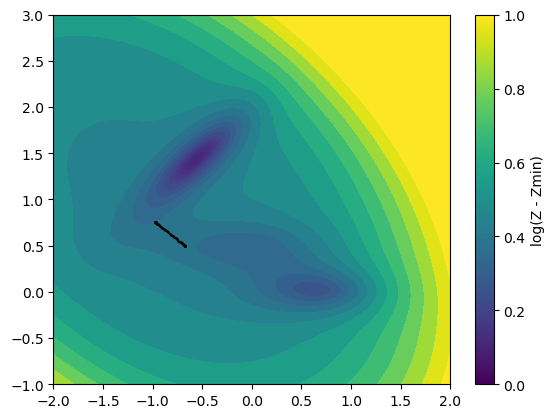

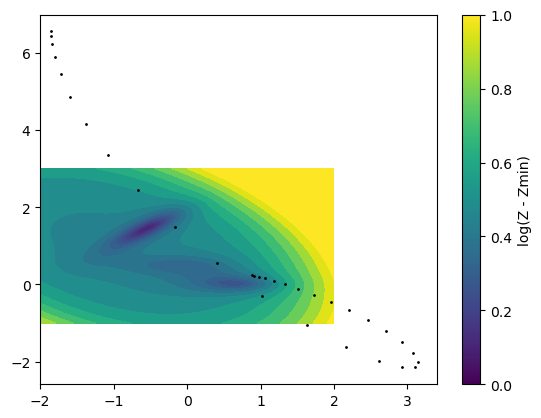

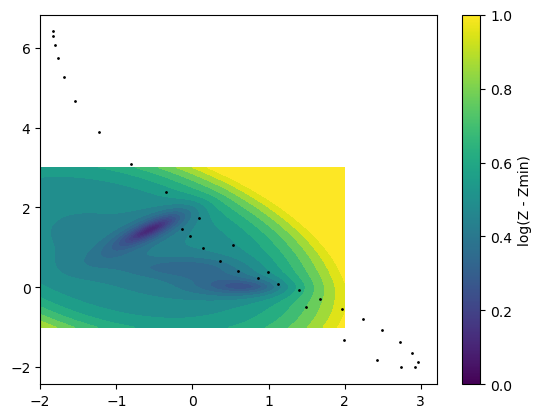

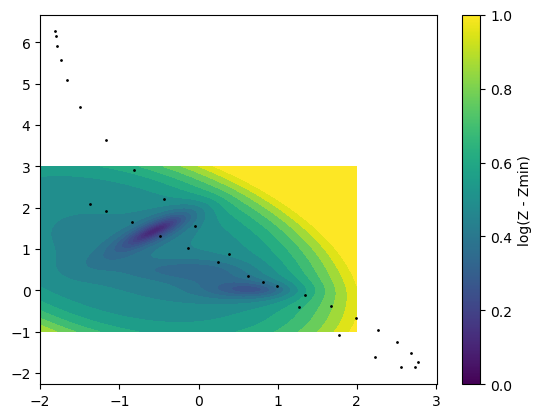

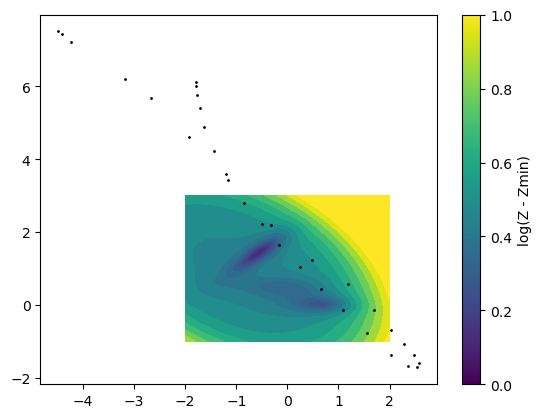

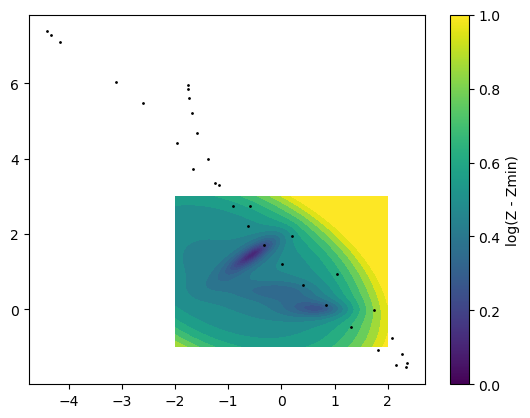

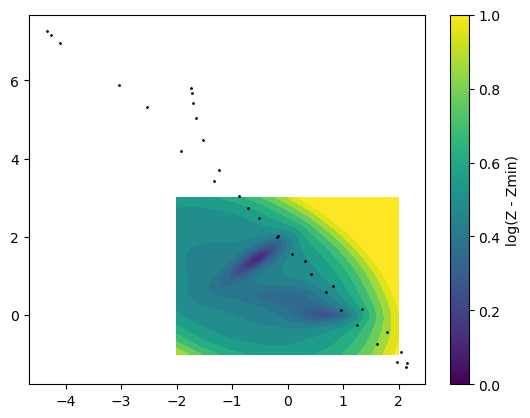

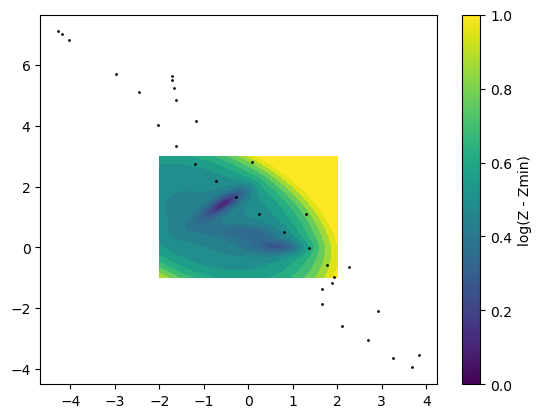

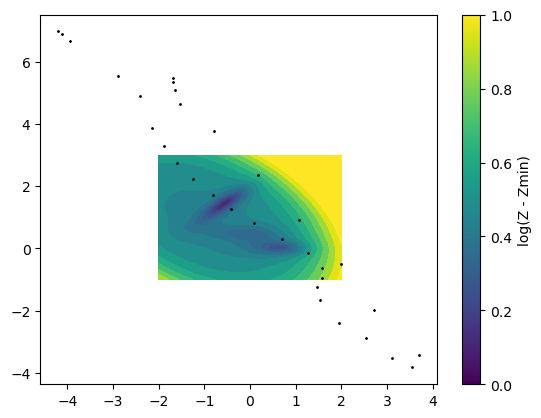

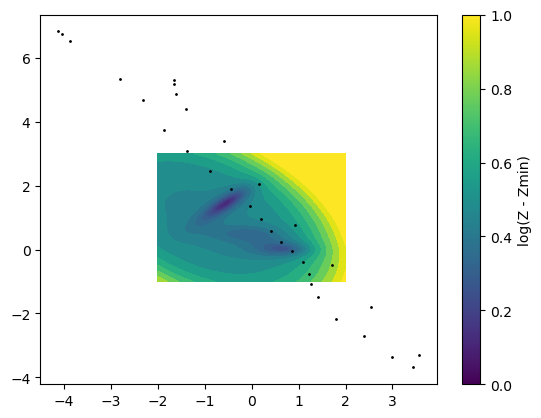

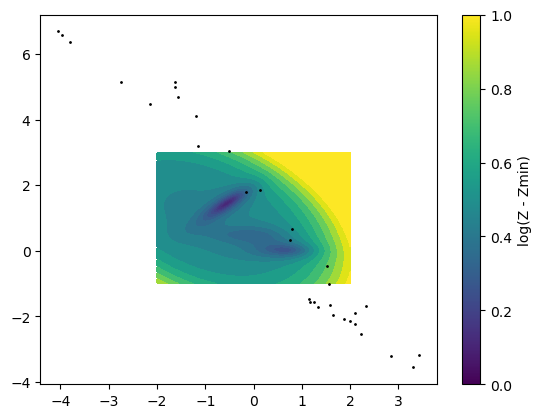

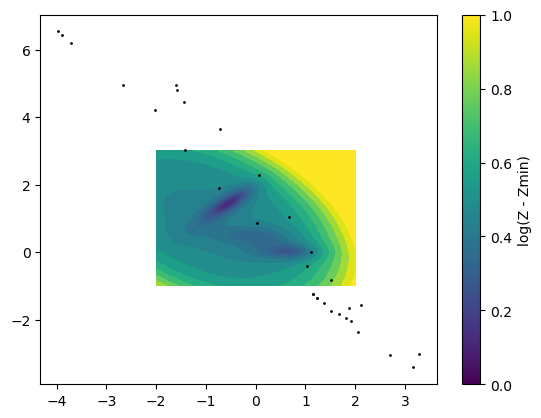

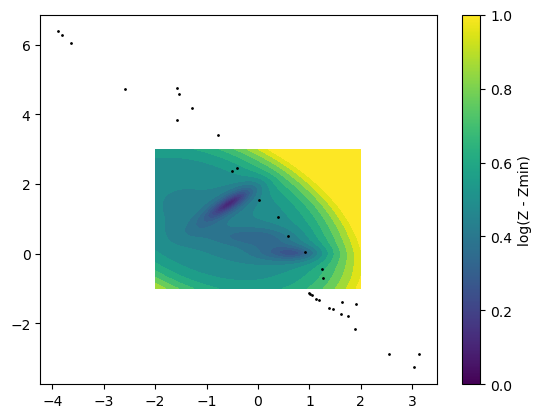

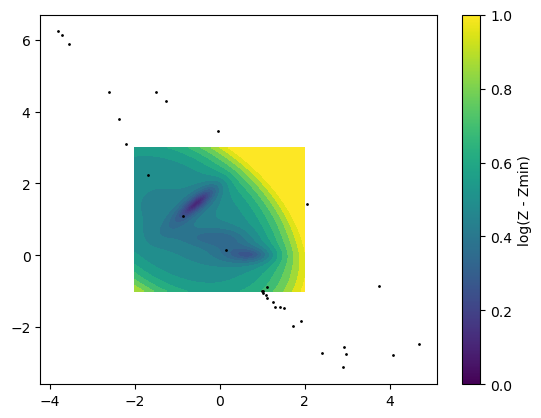

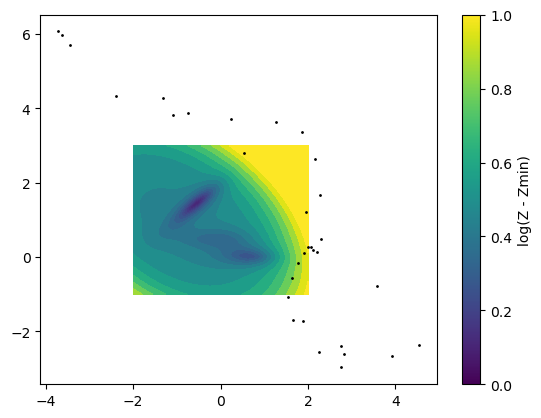

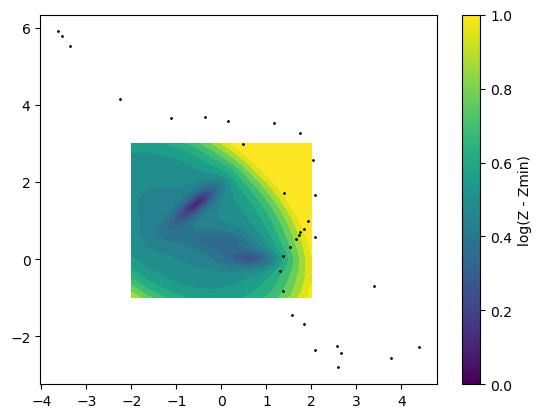

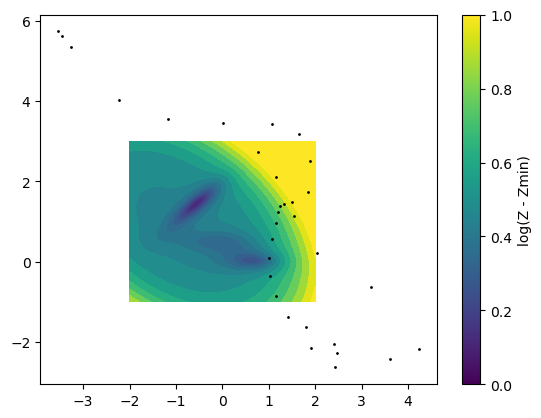

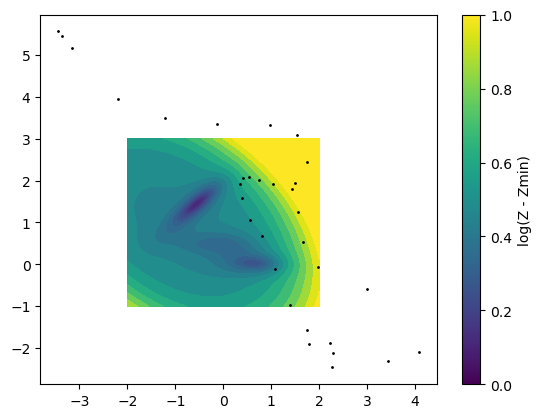

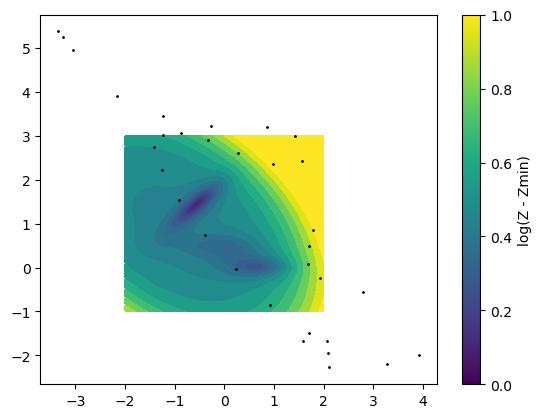

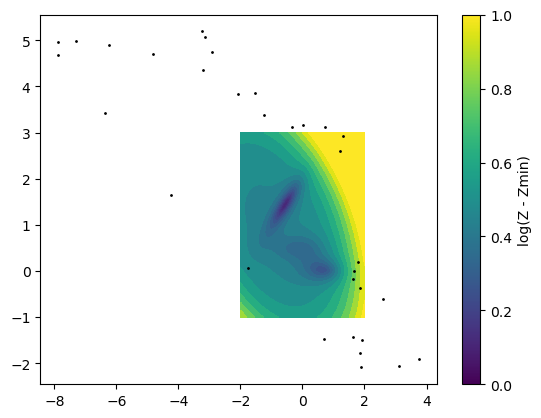

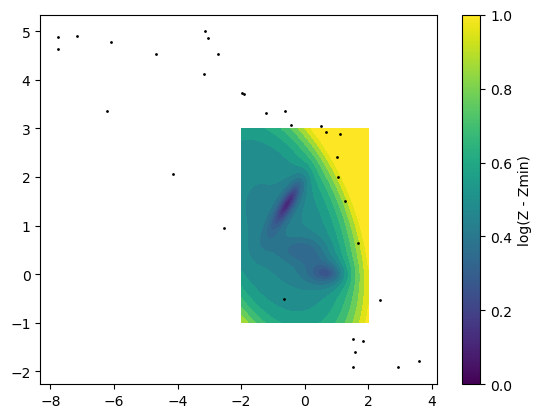

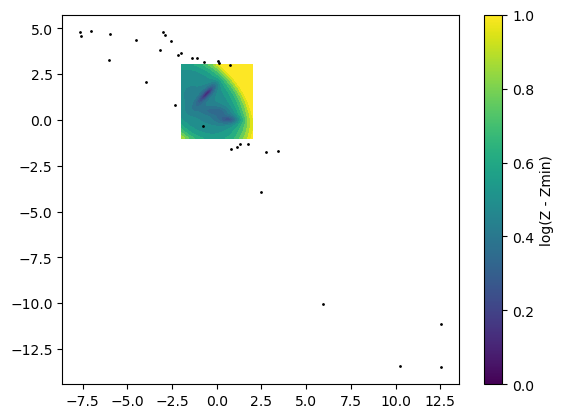

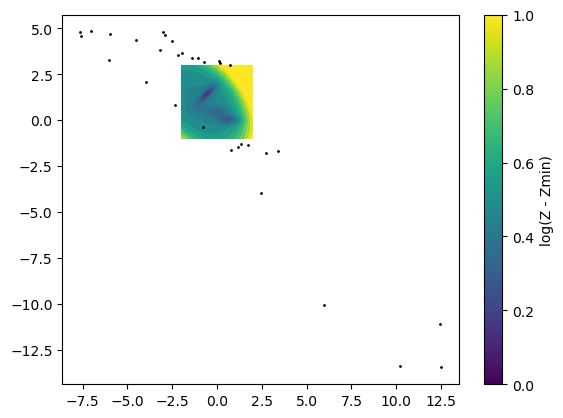

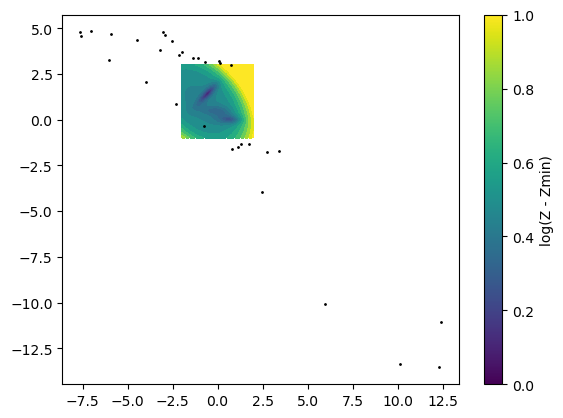

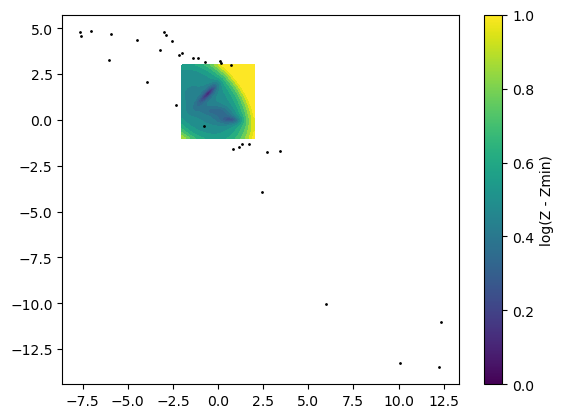

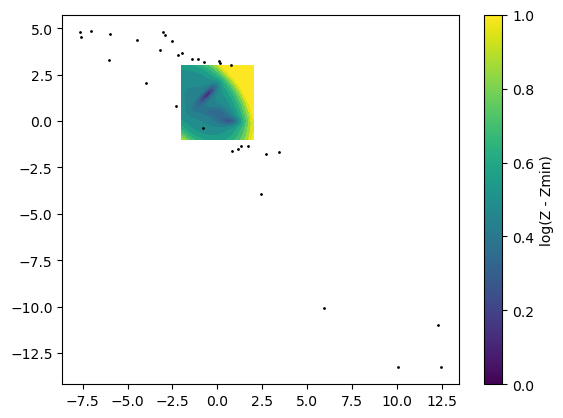

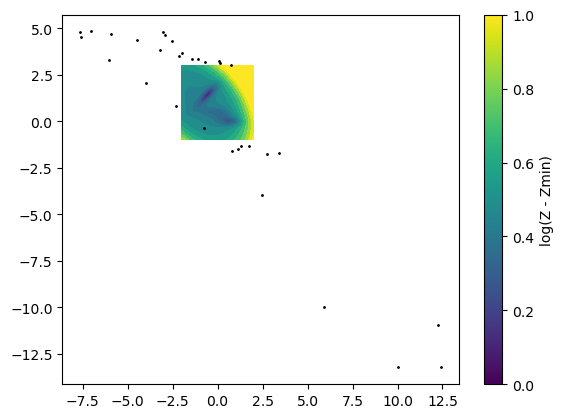

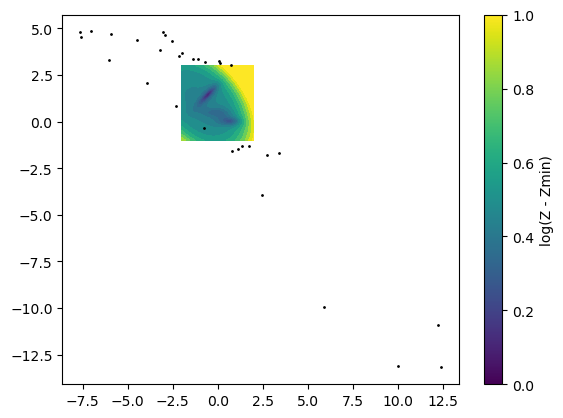

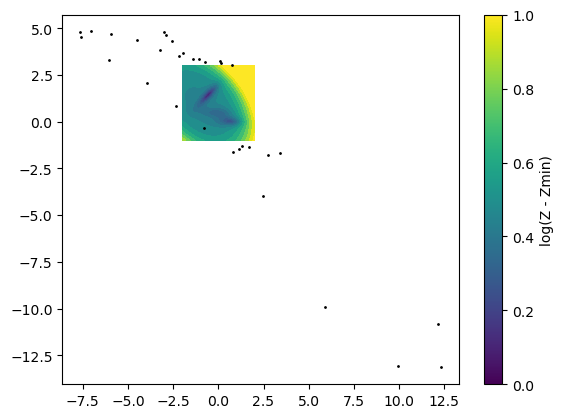

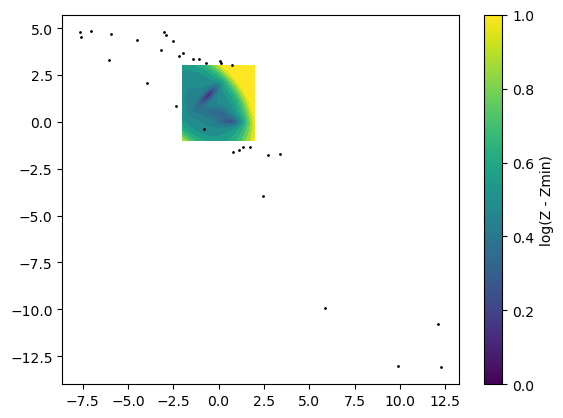

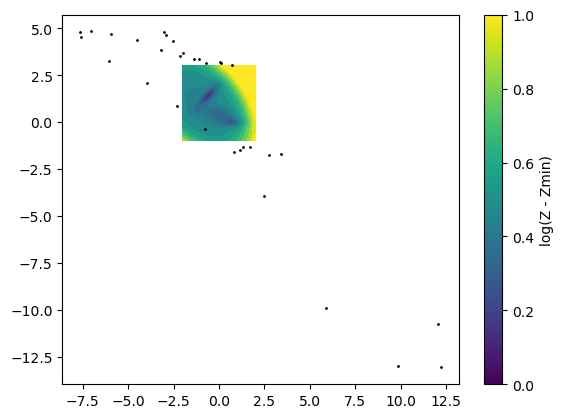

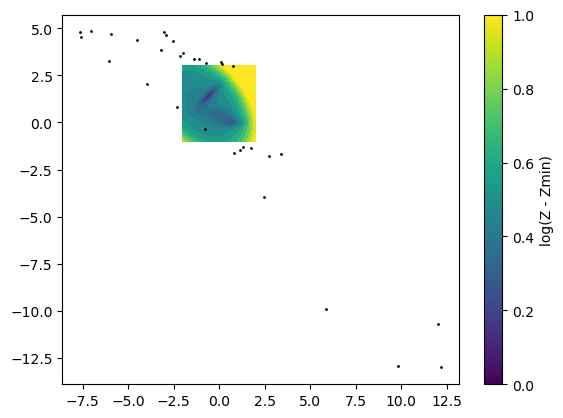

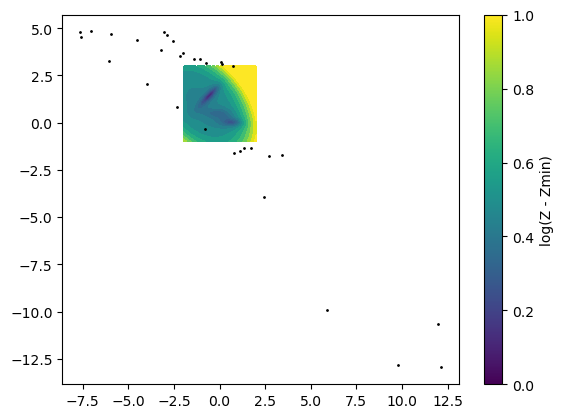

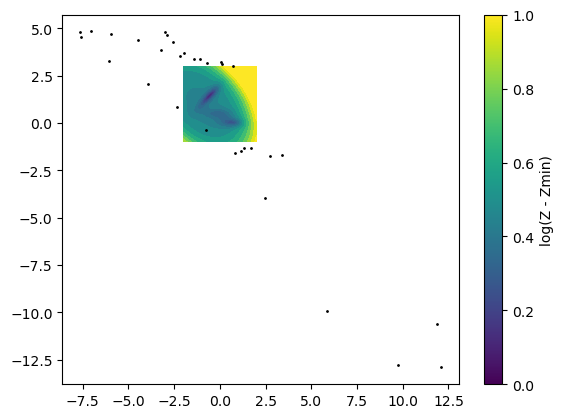

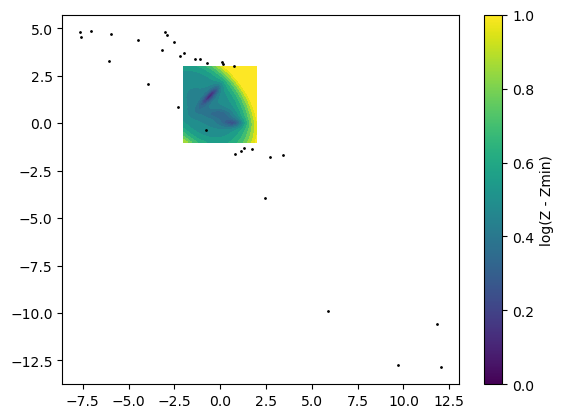

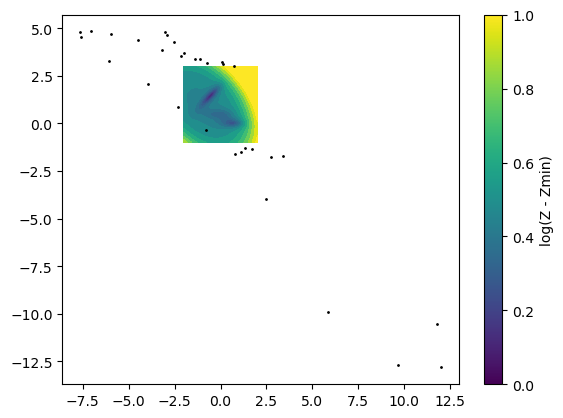

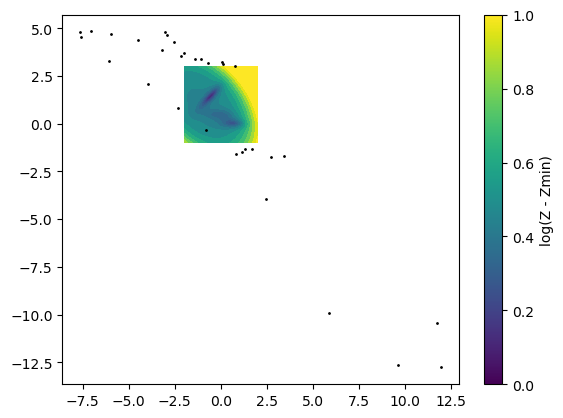

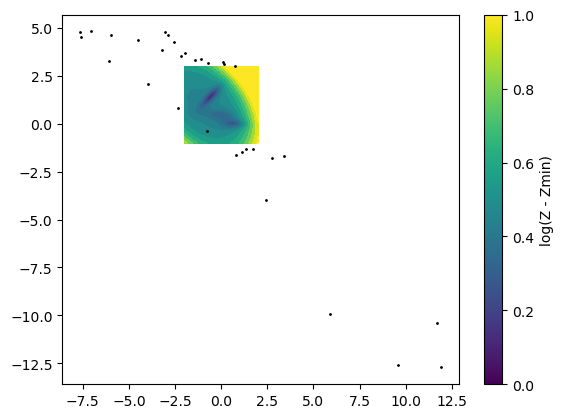

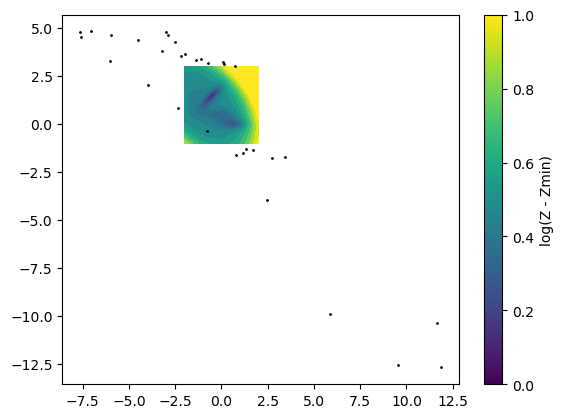

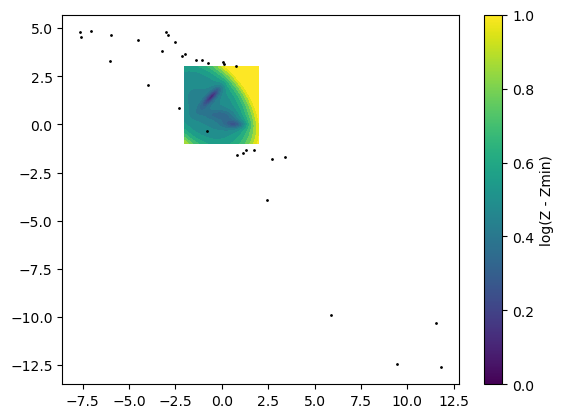

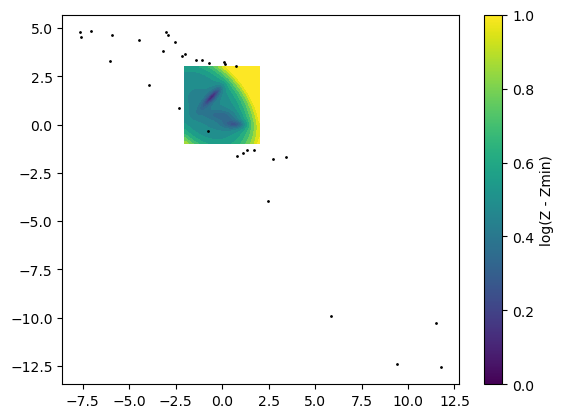

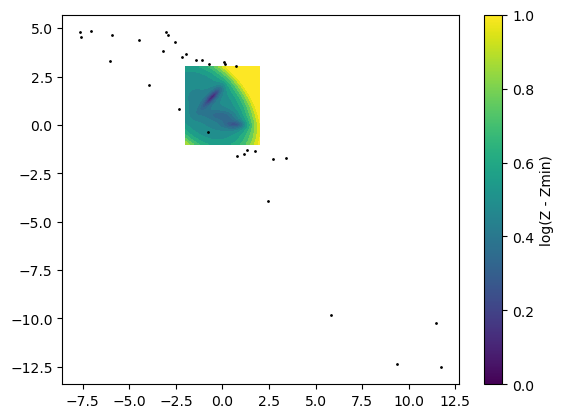

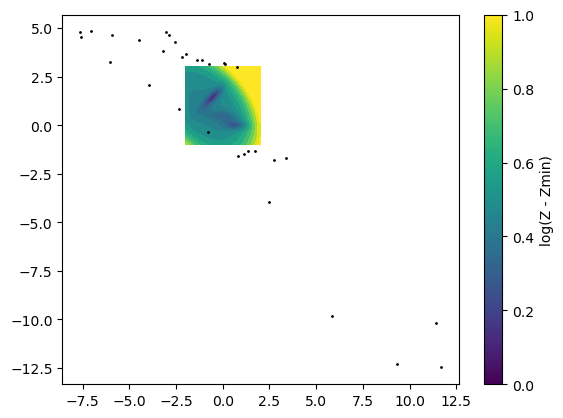

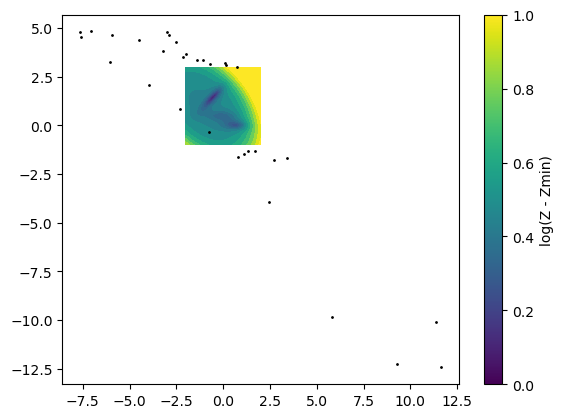

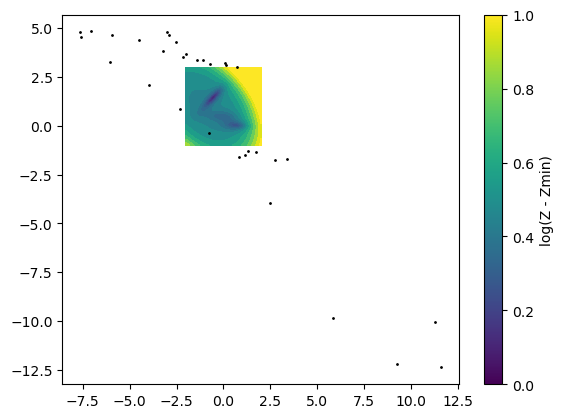

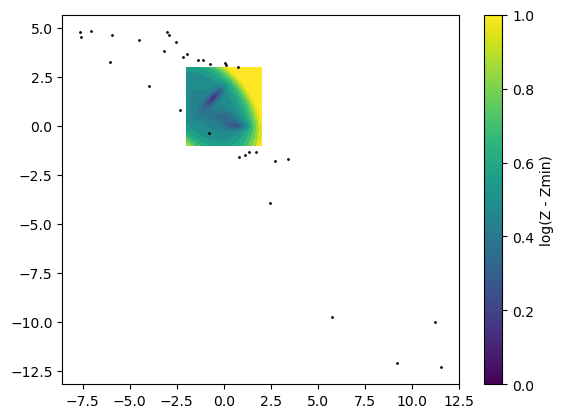

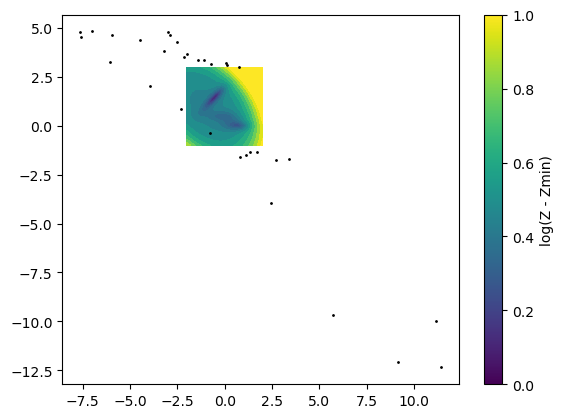

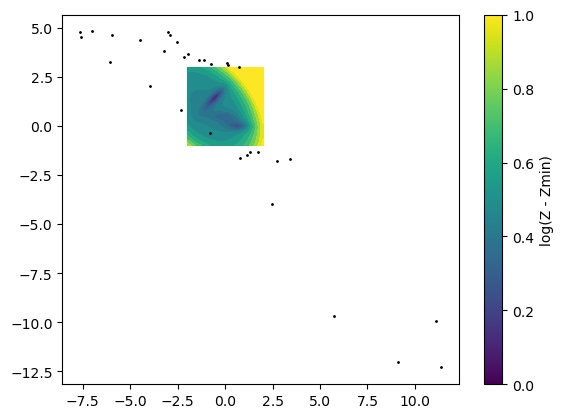

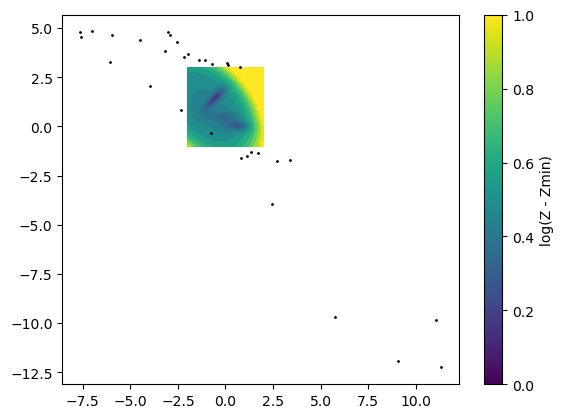

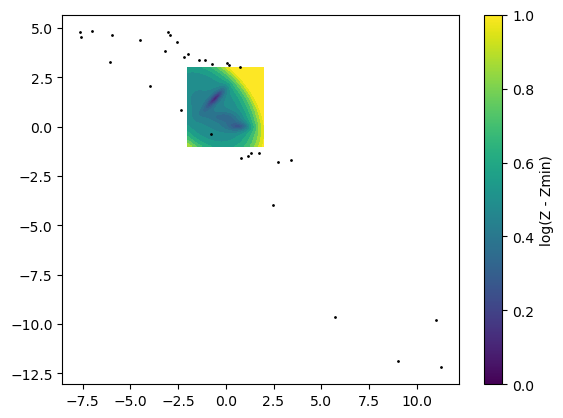

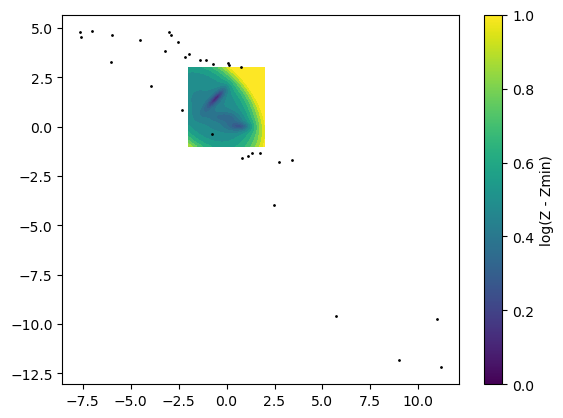

In [15]:
for i in range(len(rps)):
    show_ring_polymer_path(rps[i])